In [1]:
!pip install cdsapi netCDF4 cfgrib xarray

In [3]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
import shutil
warnings.filterwarnings('ignore')

# File paths
FEATURE_FILE = Path('final_datasets/ocean_atmos_combined_DAILY_1993_2025.nc')
OUTPUT_FILE = Path('final_datasets/ocean_atmos_DAILY_WITH_LABELS_1993_2025.nc')

# Load dataset
print("Loading dataset with features...")
ds = xr.open_dataset(FEATURE_FILE, chunks={'time': 365})

print(f"Dataset loaded: {len(ds.time)} days")
print(f"Grid: {len(ds.latitude)}×{len(ds.longitude)}")
print(f"Variables: {len(ds.data_vars)}")

# Ocean mask
ocean_mask = ds['temp_0_50m'].notnull()
ocean_points = ocean_mask.isel(time=0).sum().values
print(f"\nOcean points: {ocean_points}")

Loading dataset with features...
Dataset loaded: 12053 days
Grid: 25×49
Variables: 17

Ocean points: 924


In [4]:
# Check disk space
def check_space():
    total, used, free = shutil.disk_usage(".")
    free_gb = free / (1024**3)
    print(f"Total: {total/(1024**3):.1f} GB")
    print(f"Used: {used/(1024**3):.1f} GB")
    print(f"Free: {free_gb:.1f} GB")
    return free_gb

free_space = check_space()
if free_space < 5:
    print("WARNING: Less than 5GB free!")
else:
    print("Enough space to proceed!")

Total: 19.5 GB
Used: 12.8 GB
Free: 6.7 GB
Enough space to proceed!


In [4]:
ds.head(8)

<xarray.Dataset> Size: 35kB
Dimensions:        (time: 8, latitude: 8, longitude: 8)
Coordinates:
  * time           (time) datetime64[ns] 64B 1993-01-01 ... 1993-01-08
  * latitude       (latitude) float64 64B 37.0 36.75 36.5 ... 35.75 35.5 35.25
  * longitude      (longitude) float64 64B 24.0 24.25 24.5 ... 25.25 25.5 25.75
Data variables: (12/17)
    u10            (time, latitude, longitude) float32 2kB dask.array<chunksize=(8, 8, 8), meta=np.ndarray>
    v10            (time, latitude, longitude) float32 2kB dask.array<chunksize=(8, 8, 8), meta=np.ndarray>
    t2m            (time, latitude, longitude) float32 2kB dask.array<chunksize=(8, 8, 8), meta=np.ndarray>
    msl            (time, latitude, longitude) float32 2kB dask.array<chunksize=(8, 8, 8), meta=np.ndarray>
    sst            (time, latitude, longitude) float32 2kB dask.array<chunksize=(8, 8, 8), meta=np.ndarray>
    wind_speed     (time, latitude, longitude) float32 2kB dask.array<chunksize=(8, 8, 8), meta=np.ndarray>
    ...             ...
    temp_0_50m     (time, latitude, longitude) float32 2kB dask.array<chunksize=(8, 8, 8), meta=np.ndarray>
    temp_50_100m   (time, latitude, longitude) float32 2kB dask.array<chunksize=(8, 8, 8), meta=np.ndarray>
    temp_100_150m  (time, latitude, longitude) float32 2kB dask.array<chunksize=(8, 8, 8), meta=np.ndarray>
    ohc_0_50m      (time, latitude, longitude) float32 2kB dask.array<chunksize=(8, 8, 8), meta=np.ndarray>
    ohc_50_100m    (time, latitude, longitude) float32 2kB dask.array<chunksize=(8, 8, 8), meta=np.ndarray>
    ohc_100_150m   (time, latitude, longitude) float32 2kB dask.array<chunksize=(8, 8, 8), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-01-17T13:27 GRIB to CDM+CF via cfgrib-0.9.1...

In [5]:
def detect_mhw_hobday(temperature, window_size=11):
    """
    Detect marine heatwaves using Hobday et al. (2016) method.
    
    Parameters:
    -----------
    temperature : xarray.DataArray
        Temperature time series (daily data)
    window_size : int
        Moving window for climatology calculation (default: 11 days)
        Hobday et al. 2016 used 11-day window
    
    Returns:
    --------
    mhw_binary : xarray.DataArray
        Binary MHW occurrence (1=MHW, 0=no MHW)
    mhw_intensity : xarray.DataArray
        Temperature anomaly above threshold (°C)
    threshold : xarray.DataArray
        90th percentile threshold for each day-of-year
    climatology : xarray.DataArray
        Mean temperature for each day-of-year
    
    Reference:
    ----------
    Hobday et al. (2016) "A hierarchical approach to defining marine heatwaves"
    Progress in Oceanography, 141, 227-238
    """
    
    print(f"  Loading data into memory for processing...")
    # Load into memory to avoid dask chunking issues with quantile
    temp = temperature.load()
    
    print(f"  Computing climatology (window={window_size} days)...")
    
    # Step 1: Calculate day-of-year for all dates
    # doy = temp.time.dt.dayofyear
    temp_baseline = temp.sel(time=slice('1993-01-01', '2012-12-31'))  # baseline
    doy_baseline = temp_baseline.time.dt.dayofyear
    
    # Step 2: For each day-of-year, compute mean and 90th percentile
    # using a moving window across all years
    climatology_list = []
    threshold_list = []
    
    for target_doy in range(1, 367):  # 1 to 366 (leap years)
        if target_doy % 50 == 0:
            print(f"    Processing day {target_doy}/366...")
        
        # Create window of days around target_doy
        doy_min = target_doy - window_size // 2
        doy_max = target_doy + window_size // 2
        
        # Handle year wrapping (e.g., doy 1 includes days 360-366 from previous year)
        if doy_min < 1:
            mask = (doy_baseline >= (365 + doy_min)) | (doy_baseline <= doy_max)
        elif doy_max > 366:
            mask = (doy_baseline >= doy_min) | (doy_baseline <= (doy_max - 366))
        else:
            mask = (doy_baseline >= doy_min) & (doy_baseline <= doy_max)
        
        # Use ONLY baseline period for threshold
        temp_window = temp_baseline.where(mask, drop=False)
        # temp_window = temp.where(mask, drop=False)
        
        # Calculate climatology (mean) and threshold (90th percentile)
        clim = temp_window.mean('time', skipna=True)
        thresh = temp_window.quantile(0.9, dim='time', skipna=True)
        
        climatology_list.append(clim)
        threshold_list.append(thresh)
    
    print("  Assembling climatology and threshold arrays...")
    
    # Combine into single arrays indexed by day-of-year
    climatology = xr.concat(climatology_list, dim=pd.Index(range(1, 367), name='dayofyear'))
    threshold = xr.concat(threshold_list, dim=pd.Index(range(1, 367), name='dayofyear'))
    
    
    # Step 3: Map threshold to each date in original time series
    # print("  Mapping thresholds to daily data...")
    # threshold_daily = threshold.sel(dayofyear=doy)
    # climatology_daily = climatology.sel(dayofyear=doy)
    print("  Mapping thresholds to FULL time series...")
    doy_full = temp.time.dt.dayofyear
    threshold_daily = threshold.sel(dayofyear=doy_full)
    climatology_daily = climatology.sel(dayofyear=doy_full)
    
    # Step 4: Identify when temperature exceeds threshold
    exceeds_threshold = temp > threshold_daily
    
    # Step 5: Apply duration criterion (≥5 consecutive days)
    # Hobday et al. 2016: "MHW = ≥5 consecutive days above 90th percentile"
    print("  Applying 5-day duration criterion...")
    
    mhw_binary = identify_events_min_duration(exceeds_threshold, min_duration=5)
    
    # Step 6: Calculate intensity (°C above threshold)
    mhw_intensity = (temp - threshold_daily).where(mhw_binary == 1, 0)

    del threshold
    del climatology

    
    return mhw_binary, mhw_intensity, threshold_daily, climatology_daily


In [6]:
def identify_events_min_duration(exceeds, min_duration=5):
    """
    Apply minimum duration criterion to binary exceedance time series.
    Only events lasting ≥ min_duration days are kept as MHWs.
    
    This uses a proper event-tracking approach.
    """
    import numpy as np
    
    # Convert to numpy for easier processing
    exceeds_np = exceeds.values.astype(int)
    
    # Initialize output
    events = np.zeros_like(exceeds_np)
    
    # Process each spatial point separately
    if exceeds.ndim == 3:  # (time, lat, lon)
        for i in range(exceeds.shape[1]):
            for j in range(exceeds.shape[2]):
                events[:, i, j] = _apply_duration_1d(exceeds_np[:, i, j], min_duration)
    elif exceeds.ndim == 1:  # (time,) - single point
        events = _apply_duration_1d(exceeds_np, min_duration)
    
    # Convert back to xarray
    result = xr.DataArray(
        events,
        coords=exceeds.coords,
        dims=exceeds.dims,
        attrs=exceeds.attrs
    )
    
    return result


In [7]:
def _apply_duration_1d(exceeds_1d, min_duration):
    """
    Apply duration criterion to 1D time series.
    """
    events = np.zeros_like(exceeds_1d)
    
    # Find event boundaries
    in_event = False
    event_start = 0
    
    for t in range(len(exceeds_1d)):
        if exceeds_1d[t] == 1 and not in_event:
            # Start of potential event
            in_event = True
            event_start = t
        elif exceeds_1d[t] == 0 and in_event:
            # End of event
            event_length = t - event_start
            if event_length >= min_duration:
                # Event meets duration criterion
                events[event_start:t] = 1
            in_event = False
    
    # Handle event extending to end of time series
    if in_event:
        event_length = len(exceeds_1d) - event_start
        if event_length >= min_duration:
            events[event_start:] = 1
    
    return events


In [8]:
print("="*60)
print("DETECTING MHWs IN SST (SURFACE)")
print("="*60)

# Detect MHWs in SST
print("\nProcessing SST...")
mhw_sst, intensity_sst, threshold_sst, clim_sst = detect_mhw_hobday(ds['sst'], window_size=11)

# Add to dataset
ds['mhw_sst'] = mhw_sst
ds['mhw_sst_intensity'] = intensity_sst
ds['threshold_sst'] = threshold_sst
ds['climatology_sst'] = clim_sst

# Calculate MHW statistics
mhw_days = ds['mhw_sst'].sum('time')
total_days = len(ds.time)
mhw_percentage = (mhw_days / total_days) * 100

print(f"\nSST MHW detection complete")
print(f"  Total MHW days (spatially summed): {float(mhw_days.sum().values):,.0f}")
print(f"  Average MHW days per grid point: {float(mhw_days.mean().values):.1f} days")
print(f"  Percentage of time in MHW: {float(mhw_percentage.mean().values):.2f}%")
print(f"  Max intensity observed: {float(ds['mhw_sst_intensity'].max().values):.2f}°C")

DETECTING MHWs IN SST (SURFACE)

Processing SST...
  Loading data into memory for processing...
  Computing climatology (window=11 days)...
    Processing day 50/366...
    Processing day 100/366...
    Processing day 150/366...
    Processing day 200/366...
    Processing day 250/366...
    Processing day 300/366...
    Processing day 350/366...
  Assembling climatology and threshold arrays...
  Mapping thresholds to FULL time series...
  Applying 5-day duration criterion...

SST MHW detection complete
  Total MHW days (spatially summed): 1,809,786
  Average MHW days per grid point: 1477.4 days
  Percentage of time in MHW: 12.26%
  Max intensity observed: 3.57°C


In [9]:
print("\n" + "="*60)
print("DETECTING MHWs IN LAYER 1 (0-50m)")
print("="*60)

print("\nProcessing temp_0_50m...")
mhw_l1, intensity_l1, threshold_l1, clim_l1 = detect_mhw_hobday(ds['temp_0_50m'], window_size=11)

# Add to dataset
ds['mhw_layer1'] = mhw_l1
ds['mhw_layer1_intensity'] = intensity_l1
ds['threshold_layer1'] = threshold_l1
ds['climatology_layer1'] = clim_l1

# Statistics
mhw_days = ds['mhw_layer1'].sum('time')
mhw_percentage = (mhw_days / total_days) * 100

print(f"\nLayer 1 (0-50m) MHW detection complete")
print(f"  Total MHW days (spatially summed): {float(mhw_days.sum().values):,.0f}")
print(f"  Average MHW days per grid point: {float(mhw_days.mean().values):.1f} days")
print(f"  Percentage of time in MHW: {float(mhw_percentage.mean().values):.2f}%")
print(f"  Max intensity observed: {float(ds['mhw_layer1_intensity'].max().values):.2f}°C")


DETECTING MHWs IN LAYER 1 (0-50m)

Processing temp_0_50m...
  Loading data into memory for processing...
  Computing climatology (window=11 days)...
    Processing day 50/366...
    Processing day 100/366...
    Processing day 150/366...
    Processing day 200/366...
    Processing day 250/366...
    Processing day 300/366...
    Processing day 350/366...
  Assembling climatology and threshold arrays...
  Mapping thresholds to FULL time series...
  Applying 5-day duration criterion...

Layer 1 (0-50m) MHW detection complete
  Total MHW days (spatially summed): 1,797,110
  Average MHW days per grid point: 1467.0 days
  Percentage of time in MHW: 12.17%
  Max intensity observed: 4.18°C


In [10]:
print("\n" + "="*60)
print("DETECTING MHWs IN LAYER 2 (50-100m)")
print("="*60)

print("\nProcessing temp_50_100m...")
mhw_l2, intensity_l2, threshold_l2, clim_l2 = detect_mhw_hobday(ds['temp_50_100m'], window_size=11)

# Add to dataset
ds['mhw_layer2'] = mhw_l2
ds['mhw_layer2_intensity'] = intensity_l2
ds['threshold_layer2'] = threshold_l2
ds['climatology_layer2'] = clim_l2

# Statistics
mhw_days = ds['mhw_layer2'].sum('time')
mhw_percentage = (mhw_days / total_days) * 100

print(f"\nLayer 2 (50-100m) MHW detection complete")
print(f"  Total MHW days (spatially summed): {float(mhw_days.sum().values):,.0f}")
print(f"  Average MHW days per grid point: {float(mhw_days.mean().values):.1f} days")
print(f"  Percentage of time in MHW: {float(mhw_percentage.mean().values):.2f}%")
print(f"  Max intensity observed: {float(ds['mhw_layer2_intensity'].max().values):.2f}°C")


DETECTING MHWs IN LAYER 2 (50-100m)

Processing temp_50_100m...
  Loading data into memory for processing...
  Computing climatology (window=11 days)...
    Processing day 50/366...
    Processing day 100/366...
    Processing day 150/366...
    Processing day 200/366...
    Processing day 250/366...
    Processing day 300/366...
    Processing day 350/366...
  Assembling climatology and threshold arrays...
  Mapping thresholds to FULL time series...
  Applying 5-day duration criterion...

Layer 2 (50-100m) MHW detection complete
  Total MHW days (spatially summed): 1,591,320
  Average MHW days per grid point: 1299.0 days
  Percentage of time in MHW: 10.78%
  Max intensity observed: 5.82°C


In [11]:
print("\n" + "="*60)
print("DETECTING MHWs IN LAYER 3 (100-150m)")
print("="*60)

print("\nProcessing temp_100_150m...")
mhw_l3, intensity_l3, threshold_l3, clim_l3 = detect_mhw_hobday(ds['temp_100_150m'], window_size=11)

# Add to dataset
ds['mhw_layer3'] = mhw_l3
ds['mhw_layer3_intensity'] = intensity_l3
ds['threshold_layer3'] = threshold_l3
ds['climatology_layer3'] = clim_l3

# Statistics
mhw_days = ds['mhw_layer3'].sum('time')
mhw_percentage = (mhw_days / total_days) * 100

print(f"\nLayer 3 (100-150m) MHW detection complete")
print(f"  Total MHW days (spatially summed): {float(mhw_days.sum().values):,.0f}")
print(f"  Average MHW days per grid point: {float(mhw_days.mean().values):.1f} days")
print(f"  Percentage of time in MHW: {float(mhw_percentage.mean().values):.2f}%")
print(f"  Max intensity observed: {float(ds['mhw_layer3_intensity'].max().values):.2f}°C")


DETECTING MHWs IN LAYER 3 (100-150m)

Processing temp_100_150m...
  Loading data into memory for processing...
  Computing climatology (window=11 days)...
    Processing day 50/366...
    Processing day 100/366...
    Processing day 150/366...
    Processing day 200/366...
    Processing day 250/366...
    Processing day 300/366...
    Processing day 350/366...
  Assembling climatology and threshold arrays...
  Mapping thresholds to FULL time series...
  Applying 5-day duration criterion...

Layer 3 (100-150m) MHW detection complete
  Total MHW days (spatially summed): 1,583,674
  Average MHW days per grid point: 1292.8 days
  Percentage of time in MHW: 10.73%
  Max intensity observed: 4.30°C


In [12]:
print("\n" + "="*60)
print("COMPARISON ACROSS LAYERS")
print("="*60)

# Calculate total MHW days for each layer (ocean points only)
ocean_data = ds.where(ocean_mask, drop=False)

layers = {
    'SST': ocean_data['mhw_sst'],
    'Layer 1 (0-50m)': ocean_data['mhw_layer1'],
    'Layer 2 (50-100m)': ocean_data['mhw_layer2'],
    'Layer 3 (100-150m)': ocean_data['mhw_layer3']
}

print("\nMHW Statistics (Ocean Points Only):\n")
print(f"{'Layer':<20} {'Total Days':<15} {'Avg Days/Grid':<15} {'% Time in MHW':<15} {'Max Intensity'}")
print("-" * 85)

for layer_name, mhw_data in layers.items():
    total = float(mhw_data.sum().values)
    avg_per_grid = float(mhw_data.sum('time').mean().values)
    pct = (avg_per_grid / total_days) * 100
    
    intensity_var = layer_name.lower().replace(' ', '_').replace('(', '').replace(')', '').replace('-', '_')
    if 'sst' in intensity_var:
        max_int = float(ds['mhw_sst_intensity'].max().values)
    elif 'layer_1' in intensity_var or '0_50' in intensity_var:
        max_int = float(ds['mhw_layer1_intensity'].max().values)
    elif 'layer_2' in intensity_var or '50_100' in intensity_var:
        max_int = float(ds['mhw_layer2_intensity'].max().values)
    else:
        max_int = float(ds['mhw_layer3_intensity'].max().values)
    
    print(f"{layer_name:<20} {total:>13,.0f} {avg_per_grid:>14.1f} {pct:>14.2f}% {max_int:>13.2f}°C")

# Check surface-subsurface coupling
print("\n\nSurface-Subsurface MHW Coupling:")
print("(Percentage of time layers co-occur with SST MHW)\n")

for layer_name, mhw_data in list(layers.items())[1:]:  # Skip SST
    # Days when both SST and this layer have MHW
    concurrent = (ds['mhw_sst'] == 1) & (mhw_data == 1)
    # Days when SST has MHW
    sst_mhw = ds['mhw_sst'] == 1
    
    # Coupling percentage
    coupling = (concurrent.sum() / sst_mhw.sum() * 100).values
    print(f"  {layer_name}: {float(coupling):.1f}% of SST MHWs also occur in this layer")


COMPARISON ACROSS LAYERS

MHW Statistics (Ocean Points Only):

Layer                Total Days      Avg Days/Grid   % Time in MHW   Max Intensity
-------------------------------------------------------------------------------------
SST                      1,699,051         1387.0          11.51%          3.57°C
Layer 1 (0-50m)          1,797,110         1467.0          12.17%          4.18°C
Layer 2 (50-100m)        1,591,320         1299.0          10.78%          5.82°C
Layer 3 (100-150m)       1,583,674         1292.8          10.73%          4.30°C


Surface-Subsurface MHW Coupling:
(Percentage of time layers co-occur with SST MHW)

  Layer 1 (0-50m): 52.3% of SST MHWs also occur in this layer
  Layer 2 (50-100m): 35.7% of SST MHWs also occur in this layer
  Layer 3 (100-150m): 30.7% of SST MHWs also occur in this layer



Creating validation plots (1993-2025)...
Plot saved: mhw_detection_1993_2025.png


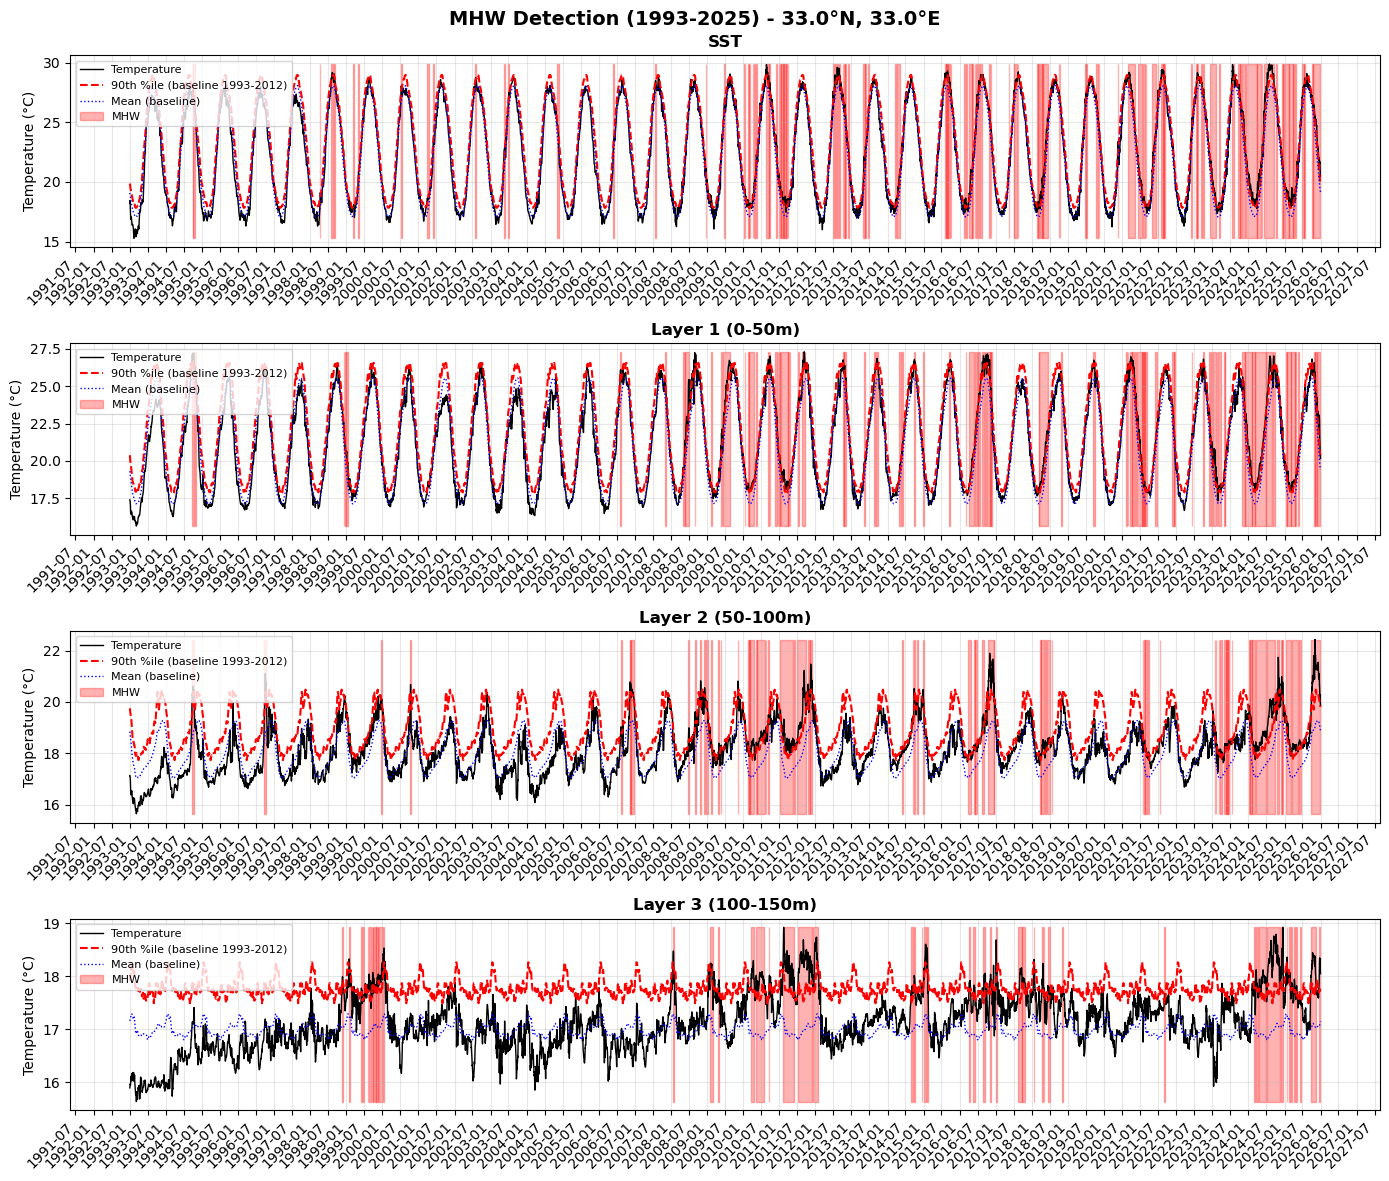

In [13]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

print("\nCreating validation plots (1993-2025)...")

# Select a point in Levantine Basin (33°N, 33°E)
point = ds.sel(latitude=33, longitude=33, method='nearest')

# Select specific time range
plot_period = point.sel(time=slice('1993-01-01', '2025-12-31'))

fig, axes = plt.subplots(4, 1, figsize=(14, 12))
fig.suptitle(f'MHW Detection (1993-2025) - {float(point.latitude):.1f}°N, {float(point.longitude):.1f}°E', 
             fontsize=14, fontweight='bold')

# Layers
layers_info = [
    ('sst', 'mhw_sst', threshold_sst, clim_sst, 'SST'),
    ('temp_0_50m', 'mhw_layer1', threshold_l1, clim_l1, 'Layer 1 (0-50m)'),
    ('temp_50_100m', 'mhw_layer2', threshold_l2, clim_l2, 'Layer 2 (50-100m)'),
    ('temp_100_150m', 'mhw_layer3', threshold_l3, clim_l3, 'Layer 3 (100-150m)')
]

for idx, (temp_var, mhw_var, thresh, clim, title) in enumerate(layers_info):
    ax = axes[idx]
    
    # Temperature data for this period
    temp_data = plot_period[temp_var]
    mhw_data = plot_period[mhw_var]
    
    # Get threshold for this location
    thresh_point = thresh.sel(latitude=point.latitude, longitude=point.longitude, method='nearest')
    clim_point = clim.sel(latitude=point.latitude, longitude=point.longitude, method='nearest')
    
    # # Map threshold to dates in plot period
    # doy_plot = plot_period.time.dt.dayofyear
    # thresh_plot = thresh_point.sel(dayofyear=doy_plot).values
    # clim_plot = clim_point.sel(dayofyear=doy_plot).values


    
    # Determine how to map threshold/climatology to the plotting times
    if 'dayofyear' in thresh_point.dims:
        # threshold indexed by dayofyear -> build daily arrays for plotting
        doy_plot = plot_period.time.dt.dayofyear
        # .sel supports a DataArray of dayofyear, xarray will align
        thresh_plot = thresh_point.sel(dayofyear=doy_plot).values
    elif 'time' in thresh_point.dims:
        # threshold already daily -> align directly
        # Try exact selection first; if time coords differ use interp
        try:
            thresh_plot = thresh_point.sel(time=plot_period.time).values
        except Exception:
            thresh_plot = thresh_point.interp(time=plot_period.time).values
    else:
        raise ValueError("Threshold array missing 'dayofyear' or 'time' dimension.")
    
    # Same for climatology
    if 'dayofyear' in clim_point.dims:
        doy_plot = plot_period.time.dt.dayofyear
        clim_plot = clim_point.sel(dayofyear=doy_plot).values
    elif 'time' in clim_point.dims:
        try:
            clim_plot = clim_point.sel(time=plot_period.time).values
        except Exception:
            clim_plot = clim_point.interp(time=plot_period.time).values
    else:
        raise ValueError("Climatology array missing 'dayofyear' or 'time' dimension.")
    
    # Get time values
    time_vals = plot_period.time.values
    
    # Plot
    ax.plot(time_vals, temp_data.values, label='Temperature', color='black', linewidth=1)
    ax.plot(time_vals, thresh_plot, label='90th %ile (baseline 1993-2012)', 
            color='red', linestyle='--', linewidth=1.5)
    ax.plot(time_vals, clim_plot, label='Mean (baseline)', 
            color='blue', linestyle=':', linewidth=1)
    
    # Shade MHW periods
    mhw_mask = mhw_data.values == 1
    if mhw_mask.any():
        ax.fill_between(time_vals, 
                        temp_data.min(), temp_data.max(),
                        where=mhw_mask,
                        alpha=0.3, color='red', label='MHW')
    
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Temperature (°C)')
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)
    
    # Format dates
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.savefig('mhw_detection_1993_2025.png', dpi=150, bbox_inches='tight')
print("Plot saved: mhw_detection_1993_2025.png")
plt.show()

In [14]:
print("\n" + "="*60)
print("SAVING LABELED DATASET")
print("="*60)

# Add metadata
ds.attrs['mhw_detection_method'] = 'Hobday et al. (2016)'
ds.attrs['mhw_detection_date'] = pd.Timestamp.now().isoformat()
ds.attrs['mhw_threshold_percentile'] = 90
ds.attrs['mhw_min_duration'] = 5
ds.attrs['mhw_climatology_window'] = 11
ds.attrs['mhw_layers'] = 'SST, 0-50m, 50-100m, 100-150m'

# List of MHW variables
mhw_vars = [
    'mhw_sst', 'mhw_sst_intensity',
    'mhw_layer1', 'mhw_layer1_intensity',
    'mhw_layer2', 'mhw_layer2_intensity',
    'mhw_layer3', 'mhw_layer3_intensity',
]

print(f"\nMHW labels created: {len(mhw_vars)} variables")
print("  Binary labels (0/1): mhw_sst, mhw_layer1, mhw_layer2, mhw_layer3")
print("  Intensity (°C above threshold): mhw_*_intensity variables")

print(f"\nSaving to: {OUTPUT_FILE}")
print("This will take 15-25 minutes...")

# Save
ds.to_netcdf(OUTPUT_FILE, mode='w')

file_size = OUTPUT_FILE.stat().st_size / 1e9
print(f"\n COMPLETE! File saved: {OUTPUT_FILE}")
print(f"File size: {file_size:.2f} GB")

print("\n" + "="*60)
print("MHW LABELING COMPLETE!")
print("="*60)


SAVING LABELED DATASET

MHW labels created: 8 variables
  Binary labels (0/1): mhw_sst, mhw_layer1, mhw_layer2, mhw_layer3
  Intensity (°C above threshold): mhw_*_intensity variables

Saving to: final_datasets/ocean_atmos_DAILY_WITH_LABELS_1993_2025.nc
This will take 15-25 minutes...

 COMPLETE! File saved: final_datasets/ocean_atmos_DAILY_WITH_LABELS_1993_2025.nc
File size: 1.85 GB

MHW LABELING COMPLETE!


In [ ]:
# Pick one grid point and plot SST vs threshold
import matplotlib.pyplot as plt

# Get one location
lat_idx = 0
lon_idx = 0

# Plot 2023–2025 SST vs threshold
test_point = test_df[
    (test_df['lat'] == test_df['lat'].unique()[lat_idx]) &
    (test_df['lon'] == test_df['lon'].unique()[lon_idx])
].sort_values('time')

plt.figure(figsize=(14, 4))
plt.plot(test_point['time'], test_point['sst'], 
         label='SST', color='red', alpha=0.7)
plt.plot(test_point['time'], test_point['threshold'], 
         label='90th pct threshold', color='blue', 
         linestyle='--')
plt.fill_between(test_point['time'],
    test_point['threshold'], test_point['sst'],
    where=(test_point[TARGET] == 1),
    alpha=0.3, color='red', label='MHW')
plt.legend()
plt.title('SST vs Threshold — Test Period 2023–2025')
plt.show()
